In [4]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.clean_data import clean_data
from src.data.load_data import load_raw_data

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

print("EDA environment initialized successfully.")

EDA environment initialized successfully.


In [5]:
#Cell 2 — Load the cleaned dataset

CLEANED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "telco_customer_churn_cleaned.csv"
)

if not CLEANED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {CLEANED_DATA_PATH}"
    )

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Dataset loaded successfully.
Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
#5.2 — Understand the dataset
#Cell 3 — Dataset overview
print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nStatistical summary of numerical features:")
display(df.describe().T)

print("\nNumber of unique values per column:")
display(
    df.nunique()
    .sort_values(ascending=False)
    .to_frame(name="Unique Values")
)

Dataset shape: (7043, 21)

Data types:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,float64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str



Statistical summary of numerical features:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80



Number of unique values per column:


,Unique Values
customerID,7043
TotalCharges,6531
MonthlyCharges,1585
tenure,73
PaymentMethod,4
StreamingMovies,3
TechSupport,3
OnlineBackup,3
StreamingTV,3
DeviceProtection,3


In [7]:
#Cell 4 — Churn distribution

churn_counts = df["Churn"].value_counts()

churn_percentages = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

target_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentages.round(2),
})

display(target_summary)

,Customer Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


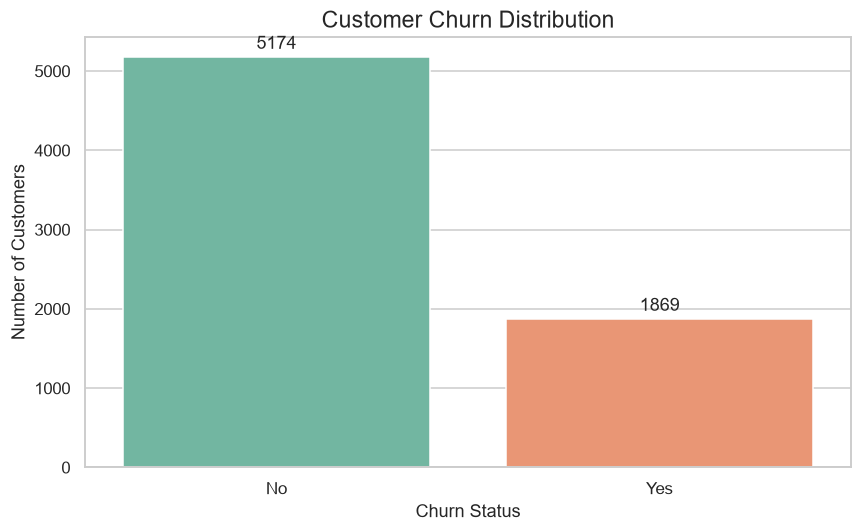

In [8]:
#Cell 5 — Visualize churn distribution

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False,
    ax=ax,
)

ax.set_title("Customer Churn Distribution", fontsize=15)
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

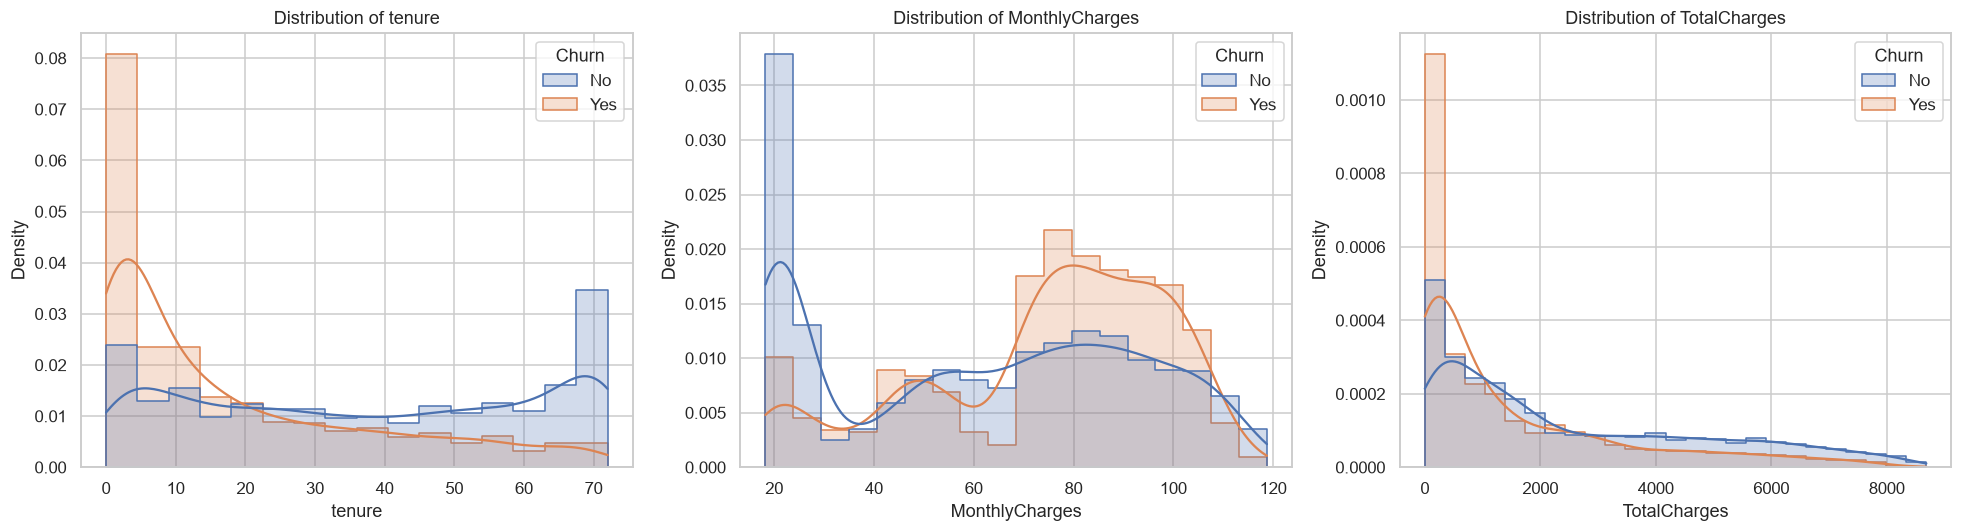

In [9]:
#5.4 — Investigate numerical features

#Cell 6 — Numerical feature distributions


numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5),
)

for ax, column in zip(axes, numerical_features):
    sns.histplot(
        data=df,
        x=column,
        hue="Churn",
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax,
    )

    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

In [10]:
#5.5 — Investigate categorical features

#We'll examine how churn varies across different customer characteristics.

#Cell 7 — Categorical churn-rate analysis
categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]

categorical_churn_results = []

for column in categorical_features:
    grouped = (
        df.groupby(column, dropna=False)["Churn"]
        .agg(
            customer_count="size",
            churn_count=lambda values: (values == "Yes").sum(),
            churn_rate=lambda values: (values == "Yes").mean() * 100,
        )
        .reset_index()
    )

    grouped.insert(0, "Feature", column)
    grouped = grouped.rename(columns={column: "Category"})

    categorical_churn_results.append(grouped)

categorical_churn_summary = pd.concat(
    categorical_churn_results,
    ignore_index=True,
)

categorical_churn_summary["churn_rate"] = (
    categorical_churn_summary["churn_rate"].round(2)
)

display(
    categorical_churn_summary.sort_values(
        ["Feature", "churn_rate"],
        ascending=[True, False],
    )
)

,Feature,Category,customer_count,churn_count,churn_rate
34,Contract,Month-to-month,3875,1655,42.71
35,Contract,One year,1473,166,11.27
36,Contract,Two year,1695,48,2.83
6,Dependents,No,4933,1543,31.28
7,Dependents,Yes,2110,326,15.45
22,DeviceProtection,No,3095,1211,39.13
24,DeviceProtection,Yes,2422,545,22.50
23,DeviceProtection,No internet service,1526,113,7.40
14,InternetService,Fiber optic,3096,1297,41.89
13,InternetService,DSL,2421,459,18.96


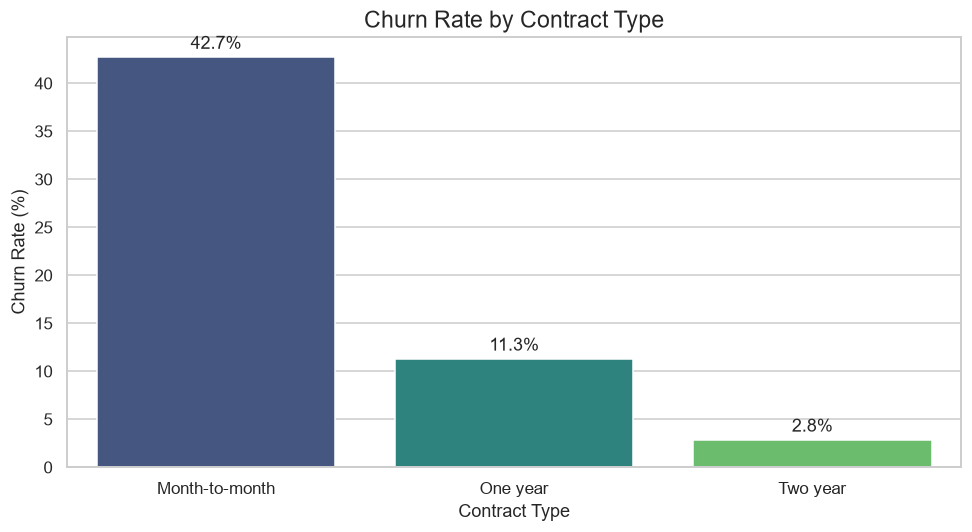

,Contract,Churn Rate (%)
0,Month-to-month,42.709677
1,One year,11.269518
2,Two year,2.831858


In [11]:
#5.6 — Visualize the most important business categories
#Cell 8 — Contract type vs churn
contract_churn = (
    df.groupby("Contract", observed=True)["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .reset_index(name="Churn Rate (%)")
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate (%)",
    hue="Contract",
    palette="viridis",
    legend=False,
    ax=ax,
)

ax.set_title("Churn Rate by Contract Type", fontsize=15)
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(contract_churn)

,mean,median,std
Churn,,,
No,37.57,38.0,24.11
Yes,17.98,10.0,19.53


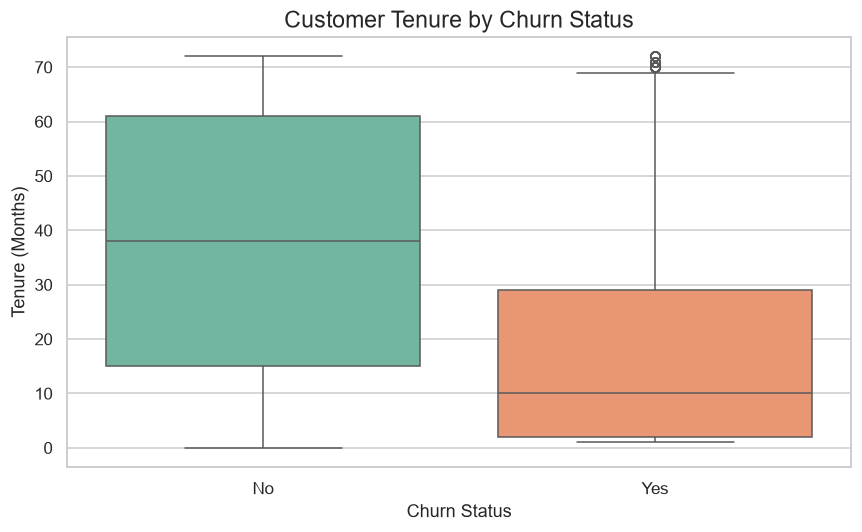

In [12]:
#Cell 9 — Tenure vs churn
tenure_churn = (
    df.groupby("Churn")["tenure"]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(tenure_churn)

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False,
    ax=ax,
)

ax.set_title("Customer Tenure by Churn Status", fontsize=15)
ax.set_xlabel("Churn Status")
ax.set_ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

,mean,median,std
Churn,,,
No,61.27,64.43,31.09
Yes,74.44,79.65,24.67


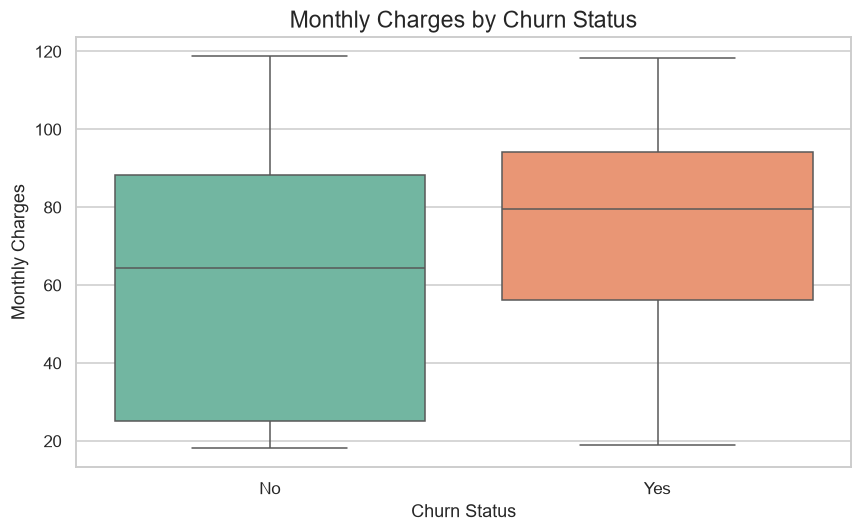

In [13]:
#Cell 10 — Monthly charges vs churn
monthly_charge_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(monthly_charge_summary)

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False,
    ax=ax,
)

ax.set_title("Monthly Charges by Churn Status", fontsize=15)
ax.set_xlabel("Churn Status")
ax.set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.103
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.103,0.826,0.651,1.000


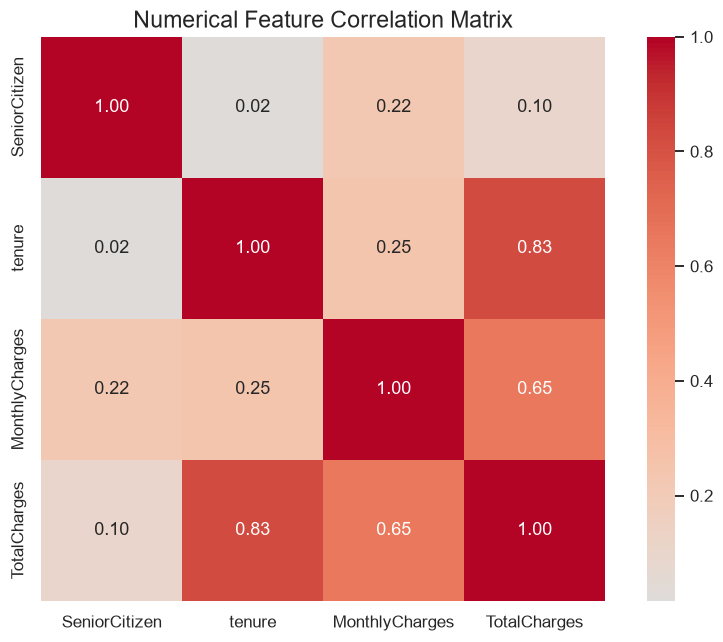

In [14]:
#5.7 — Investigate correlations
# Cell 11 — Numerical correlation matrix
correlation_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

correlation_matrix = df[correlation_features].corr()

display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    ax=ax,
)

ax.set_title("Numerical Feature Correlation Matrix", fontsize=15)

plt.tight_layout()
plt.show()

In [15]:
# save the eda output
#Cell 12 — Export analytical tables and charts


EDA_DIR = PROJECT_ROOT / "reports" / "eda"
FIGURES_DIR = EDA_DIR / "figures"
TABLES_DIR = EDA_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Save analytical tables
target_summary.to_csv(
    TABLES_DIR / "target_distribution.csv"
)

categorical_churn_summary.to_csv(
    TABLES_DIR / "categorical_churn_analysis.csv",
    index=False,
)

contract_churn.to_csv(
    TABLES_DIR / "contract_churn_rates.csv",
    index=False,
)

monthly_charge_summary.to_csv(
    TABLES_DIR / "monthly_charges_by_churn.csv"
)

tenure_churn.to_csv(
    TABLES_DIR / "tenure_by_churn.csv"
)

correlation_matrix.to_csv(
    TABLES_DIR / "numerical_correlation_matrix.csv"
)

print("EDA tables saved to:", TABLES_DIR)

EDA tables saved to: c:\Users\moham\Desktop\SLA\projects\Customer_churn_prediction\reports\eda\tables
